# Supermarket Sales Analysis
### Data Cleaning, Preprocessing & Exploratory Data Analysis (EDA)

This notebook analyzes supermarket transactions to understand sales performance, product-line performance, customer purchasing patterns, payment preferences, and customer ratings.

**Workflow**
1. Data loading and inspection
2. Data cleaning and preprocessing
3. Feature engineering and KPI creation
4. Exploratory Data Analysis (EDA)
5. Key findings and next steps

> **Dataset requirement:** Place `supermarket_sales.csv` in the same folder as this notebook. The charts use Matplotlib and Seaborn so they can render as static outputs in GitHub after you run and save the notebook.

## 1. Import Libraries

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", None)

## 2. Load the Dataset

In [2]:
# The CSV should be in the same folder as this notebook.
DATA_FILE = "supermarket_sales.csv"

if not os.path.exists(DATA_FILE):
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE!r}. Current folder: {os.getcwd()}. "
        "Place the CSV in this folder or update DATA_FILE to its full path."
    )

df_raw = pd.read_csv(DATA_FILE)
df = df_raw.copy()

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 1,000 rows × 17 columns


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,01-05-2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,03-08-2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,03-03-2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,02-08-2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


## 3. Data Understanding — Before Cleaning

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Column names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null 

In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice ID,1000,1000,849-09-3807,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Branch,1000,3,A,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,1000,3,Yangon,340,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer type,1000,2,Member,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,1000,2,Female,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product line,1000,6,Fashion accessories,178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unit price,1000.0,NaN,NaN,NaN,55.67213,26.494628,10.08,32.875,55.23,77.935,99.96
Quantity,1000.0,NaN,NaN,NaN,5.51,2.923431,1.0,3.0,5.0,8.0,10.0
Tax 5%,1000.0,NaN,NaN,NaN,15.379369,11.708825,0.5085,5.924875,12.088,22.44525,49.65
Total,1000.0,NaN,NaN,NaN,322.966749,245.885335,10.6785,124.422375,253.848,471.35025,1042.65


In [5]:
missing_before = df.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0].rename("Missing values").to_frame())
print(f"Exact duplicate rows: {df.duplicated().sum()}")

,Missing values


Exact duplicate rows: 0


## 4. Data Cleaning

This section checks column names, duplicate records, missing values, and data types. It avoids deleting useful fields such as `Invoice ID` and `Time` from the working dataset; those fields can be excluded from specific charts when they are not analytical measures.

In [6]:
# Normalize accidental whitespace in column names and text values.
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

# Remove exact duplicate records, if any.
duplicate_count = int(df.duplicated().sum())
if duplicate_count:
    df = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {duplicate_count}")

# Parse date and time safely where those columns exist.
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=False)

if "Time" in df.columns:
    # Keep the original Time column and create a numeric hour feature later.
    df["Time"] = df["Time"].astype("string").str.strip()

# Convert expected numeric fields to numeric values if present.
numeric_candidates = [
    "Unit price", "Quantity", "Tax 5%", "Total", "cogs",
    "gross margin percentage", "gross income", "Rating"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print(f"Shape after basic cleaning: {df.shape}")

Exact duplicate rows removed: 0
Shape after basic cleaning: (1000, 17)


In [7]:
# Review missing values after type conversion.
missing_after = df.isna().sum().sort_values(ascending=False)
display(missing_after[missing_after > 0].rename("Missing values").to_frame())

# Do not silently impute or drop rows: inspect missingness first.

,Missing values
Date,587


## 5. Data Preprocessing & Feature Engineering

In [8]:
# Work on rows with valid dates for date-based analysis; preserve df for general analysis.
if "Date" in df.columns:
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Month Name"] = df["Date"].dt.strftime("%b")
    df["Day"] = df["Date"].dt.day
    df["Day Name"] = df["Date"].dt.day_name()
    df["Weekday/Weekend"] = np.where(df["Date"].dt.dayofweek >= 5, "Weekend", "Weekday")

if "Time" in df.columns:
    parsed_time = pd.to_datetime(df["Time"], format="%H:%M", errors="coerce")
    df["Hour"] = parsed_time.dt.hour

# Calculate revenue from unit price × quantity where the fields are available.
if {"Unit price", "Quantity"}.issubset(df.columns):
    df["Calculated Sales"] = df["Unit price"] * df["Quantity"]

print("New analytical features created where source columns were available.")
display(df.head())

New analytical features created where source columns were available.


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating,Year,Month,Month Name,Day,Day Name,Weekday/Weekend,Hour,Calculated Sales
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05,13:08,Ewallet,522.83,4.761905,26.1415,9.1,2019.0,1.0,Jan,5.0,Saturday,Weekend,13,522.83
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,2019-03-08,10:29,Cash,76.40,4.761905,3.8200,9.6,2019.0,3.0,Mar,8.0,Friday,Weekday,10,76.40
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03,13:23,Credit card,324.31,4.761905,16.2155,7.4,2019.0,3.0,Mar,3.0,Sunday,Weekend,13,324.31
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,NaT,20:33,Ewallet,465.76,4.761905,23.2880,8.4,NaN,NaN,NaN,NaN,NaN,Weekday,20,465.76
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08,10:37,Ewallet,604.17,4.761905,30.2085,5.3,2019.0,2.0,Feb,8.0,Friday,Weekday,10,604.17


In [9]:
# Create a compact quality summary for transparency.
quality_summary = pd.DataFrame({
    "Metric": ["Rows in raw file", "Rows after exact-deduplication", "Columns after preprocessing"],
    "Value": [len(df_raw), len(df), df.shape[1]]
})
display(quality_summary)

,Metric,Value
0,Rows in raw file,1000
1,Rows after exact-deduplication,1000
2,Columns after preprocessing,25


## 6. Exploratory Data Analysis (EDA)

The charts below focus on interpretable business questions. Revenue is calculated from `Unit price × Quantity` when those columns exist; if the dataset contains a `Total` column, it is also used for comparison.

### 6.1 Key Performance Indicators (KPIs)

In [10]:
# Select a sales measure that is available in the dataset.
if "Total" in df.columns:
    sales_col = "Total"
elif "Calculated Sales" in df.columns:
    sales_col = "Calculated Sales"
else:
    sales_col = None

kpis = {}
kpis["Transactions"] = len(df)
if sales_col:
    kpis["Total Sales"] = df[sales_col].sum()
    kpis["Average Transaction"] = df[sales_col].mean()
if "gross income" in df.columns:
    kpis["Total Gross Income"] = df["gross income"].sum()
if "Rating" in df.columns:
    kpis["Average Rating"] = df["Rating"].mean()

for name, value in kpis.items():
    if isinstance(value, (int, np.integer)):
        print(f"{name}: {value:,.0f}")
    elif isinstance(value, (float, np.floating)):
        print(f"{name}: {value:,.2f}")
    else:
        print(f"{name}: {value}")

Transactions: 1,000
Total Sales: 322,966.75
Average Transaction: 322.97
Total Gross Income: 15,379.37
Average Rating: 6.97


### 6.2 Sales by Product Line

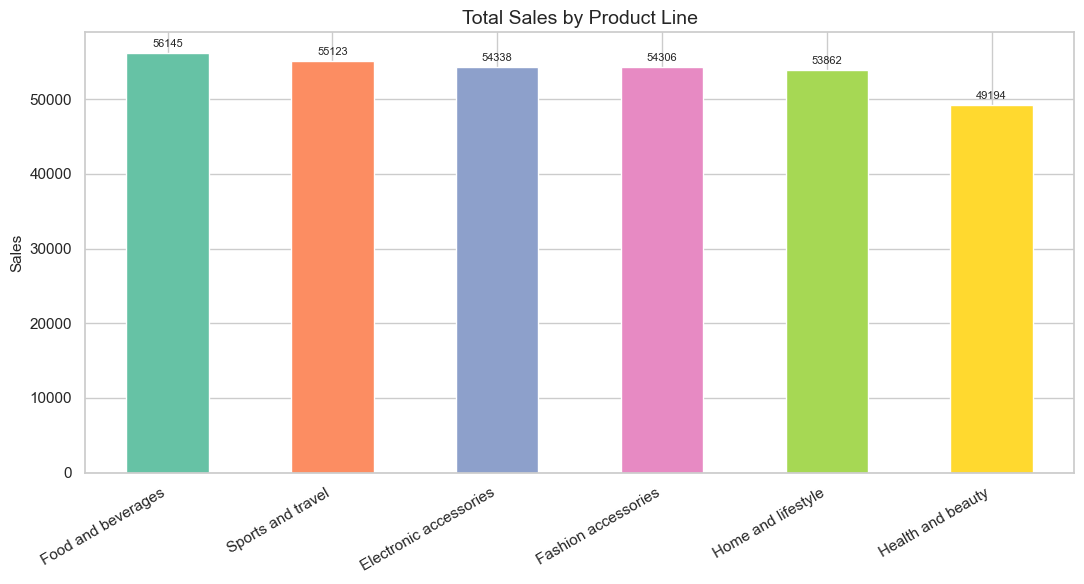

In [11]:
if "Product line" in df.columns and sales_col:
    sales_product = df.groupby("Product line")[sales_col].sum().sort_values(ascending=False)
    ax = sales_product.plot(kind="bar", figsize=(11, 6), color=sns.color_palette("Set2", len(sales_product)))
    ax.set_title("Total Sales by Product Line")
    ax.set_xlabel("")
    ax.set_ylabel("Sales")
    plt.xticks(rotation=30, ha="right")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("Required columns 'Product line' and a sales measure are not available.")

### 6.3 Sales by City

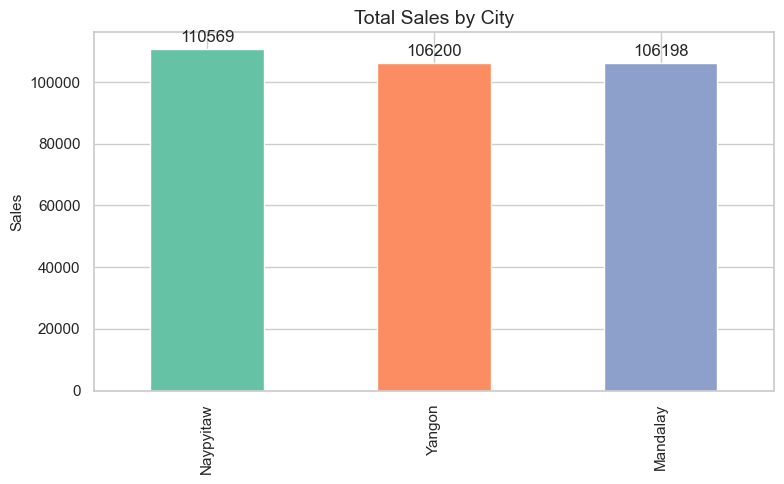

In [12]:
if "City" in df.columns and sales_col:
    sales_city = df.groupby("City")[sales_col].sum().sort_values(ascending=False)
    ax = sales_city.plot(kind="bar", figsize=(8, 5), color=sns.color_palette("Set2", len(sales_city)))
    ax.set_title("Total Sales by City")
    ax.set_xlabel("")
    ax.set_ylabel("Sales")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.tight_layout()
    plt.show()

### 6.4 Monthly Sales Trend

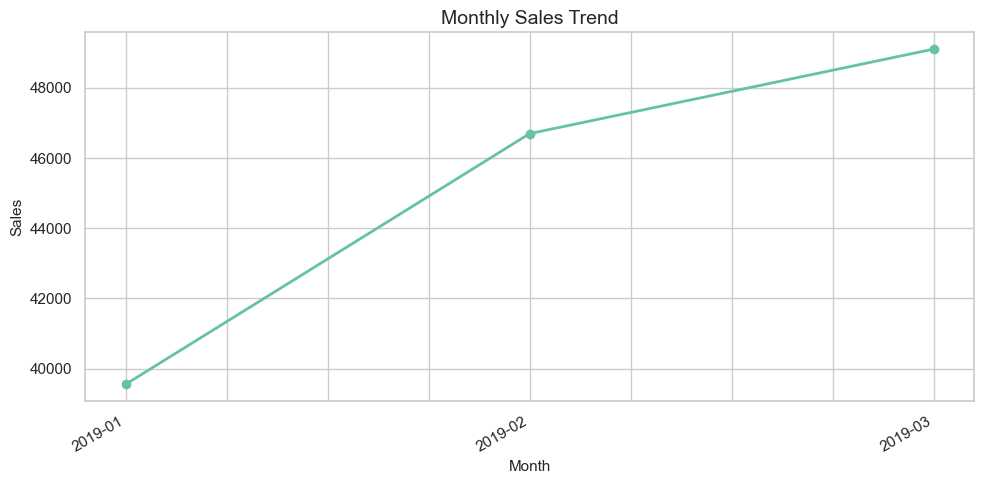

In [13]:
if {"Date"}.issubset(df.columns) and sales_col:
    dated = df.dropna(subset=["Date"]).copy()
    monthly_sales = dated.groupby(dated["Date"].dt.to_period("M"))[sales_col].sum()
    if not monthly_sales.empty:
        monthly_sales.index = monthly_sales.index.astype(str)
        ax = monthly_sales.plot(marker="o", linewidth=2, figsize=(10, 5))
        ax.set_title("Monthly Sales Trend")
        ax.set_xlabel("Month")
        ax.set_ylabel("Sales")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

### 6.5 Transaction Count by Payment Method

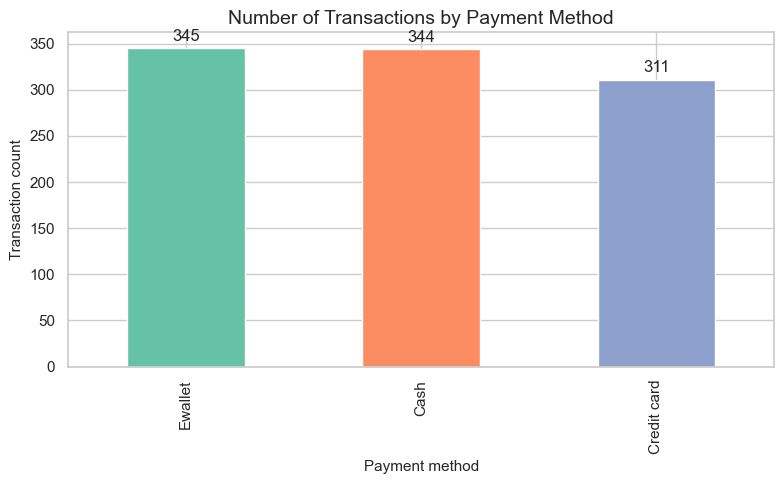

In [14]:
if "Payment" in df.columns:
    payment_counts = df["Payment"].value_counts()
    ax = payment_counts.plot(kind="bar", figsize=(8, 5), color=sns.color_palette("Set2", len(payment_counts)))
    ax.set_title("Number of Transactions by Payment Method")
    ax.set_xlabel("Payment method")
    ax.set_ylabel("Transaction count")
    for container in ax.containers:
        ax.bar_label(container, padding=3)
    plt.tight_layout()
    plt.show()

### 6.6 Sales by Customer Type

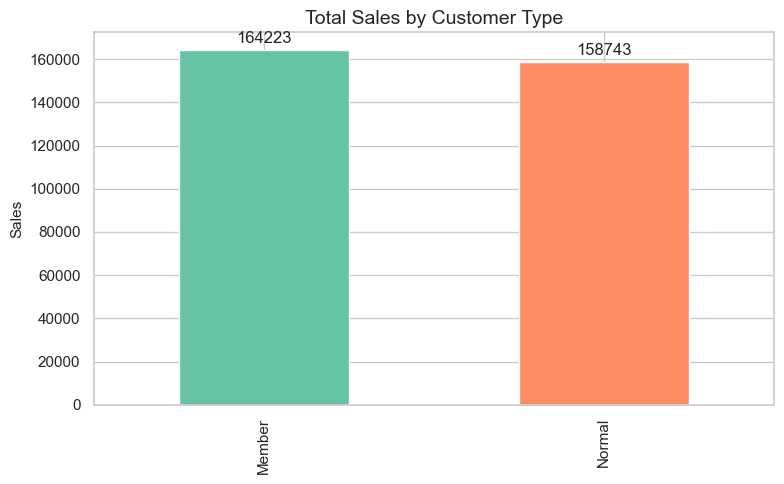

In [15]:
if "Customer type" in df.columns and sales_col:
    customer_sales = df.groupby("Customer type")[sales_col].sum().sort_values(ascending=False)
    ax = customer_sales.plot(kind="bar", figsize=(8, 5), color=sns.color_palette("Set2", len(customer_sales)))
    ax.set_title("Total Sales by Customer Type")
    ax.set_xlabel("")
    ax.set_ylabel("Sales")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.tight_layout()
    plt.show()

### 6.7 Sales by Gender

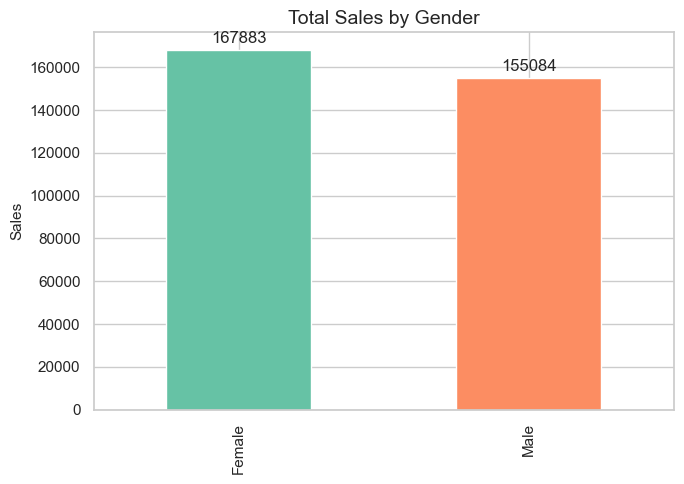

In [16]:
if "Gender" in df.columns and sales_col:
    gender_sales = df.groupby("Gender")[sales_col].sum().sort_values(ascending=False)
    ax = gender_sales.plot(kind="bar", figsize=(7, 5), color=sns.color_palette("Set2", len(gender_sales)))
    ax.set_title("Total Sales by Gender")
    ax.set_xlabel("")
    ax.set_ylabel("Sales")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)
    plt.tight_layout()
    plt.show()

### 6.8 Sales by Hour of Day

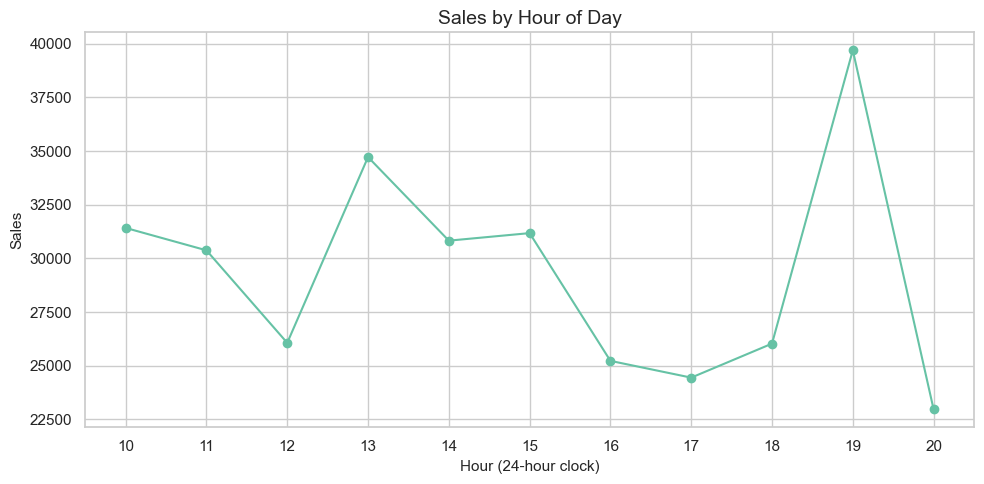

In [17]:
if "Hour" in df.columns and sales_col:
    hourly_sales = df.dropna(subset=["Hour"]).groupby("Hour")[sales_col].sum().sort_index()
    if not hourly_sales.empty:
        ax = hourly_sales.plot(kind="line", marker="o", figsize=(10, 5))
        ax.set_title("Sales by Hour of Day")
        ax.set_xlabel("Hour (24-hour clock)")
        ax.set_ylabel("Sales")
        ax.set_xticks(sorted(hourly_sales.index.astype(int).unique()))
        plt.tight_layout()
        plt.show()
else:
    print("Hourly analysis requires a valid Time column.")

### 6.9 Average Customer Rating by Product Line

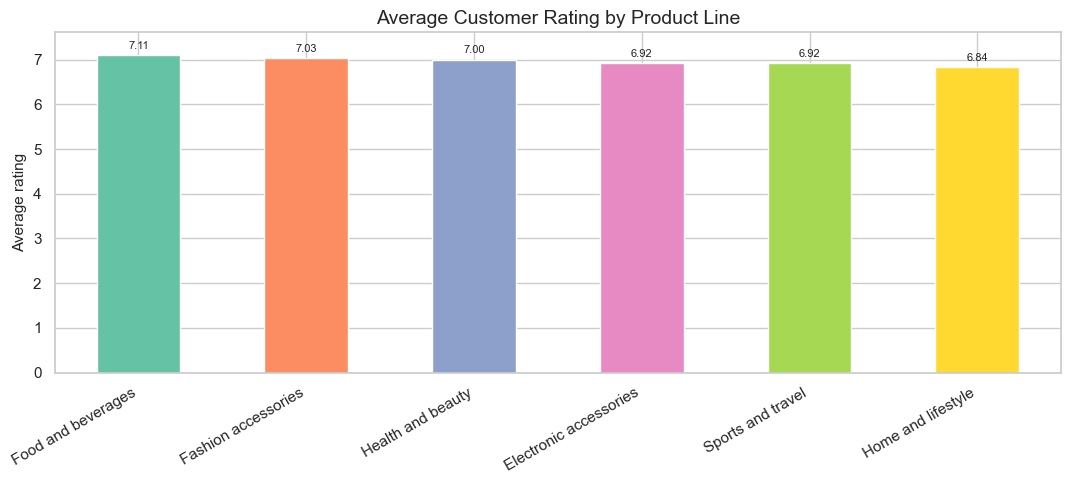

In [18]:
if {"Product line", "Rating"}.issubset(df.columns):
    rating_product = df.groupby("Product line")["Rating"].mean().sort_values(ascending=False)
    ax = rating_product.plot(kind="bar", figsize=(11, 5), color=sns.color_palette("Set2", len(rating_product)))
    ax.set_title("Average Customer Rating by Product Line")
    ax.set_xlabel("")
    ax.set_ylabel("Average rating")
    ax.set_ylim(0, max(5, rating_product.max() + 0.5))
    plt.xticks(rotation=30, ha="right")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", padding=3, fontsize=8)
    plt.tight_layout()
    plt.show()

### 6.10 Unit Price Distribution

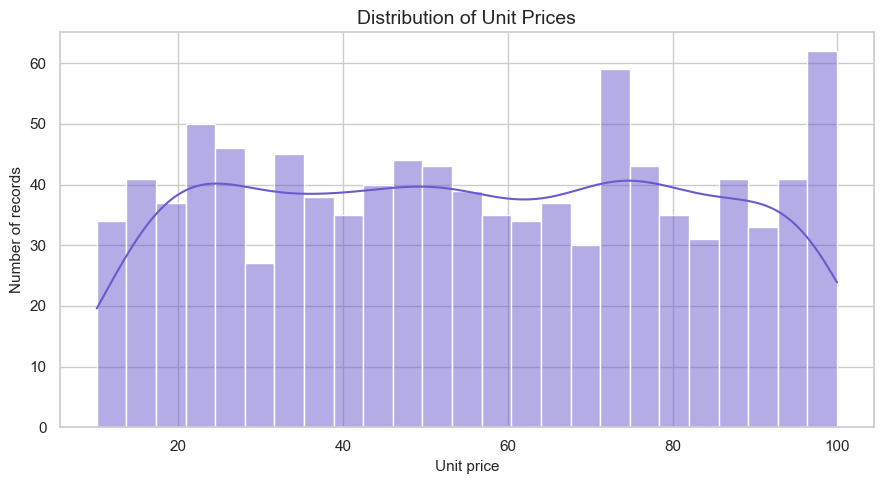

In [19]:
if "Unit price" in df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(data=df, x="Unit price", bins=25, kde=True, color="slateblue")
    plt.title("Distribution of Unit Prices")
    plt.xlabel("Unit price")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()

### 6.11 Unit Price by Product Line

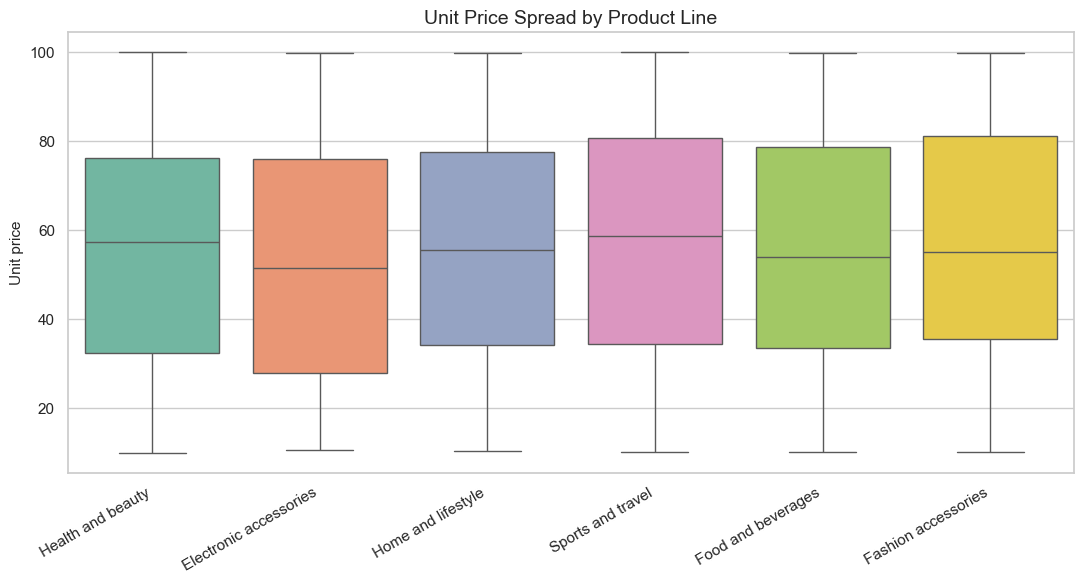

In [20]:
if {"Product line", "Unit price"}.issubset(df.columns):
    plt.figure(figsize=(11, 6))
    sns.boxplot(data=df, x="Product line", y="Unit price", hue="Product line", legend=False)
    plt.title("Unit Price Spread by Product Line")
    plt.xlabel("")
    plt.ylabel("Unit price")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

### 6.12 Quantity vs Sales

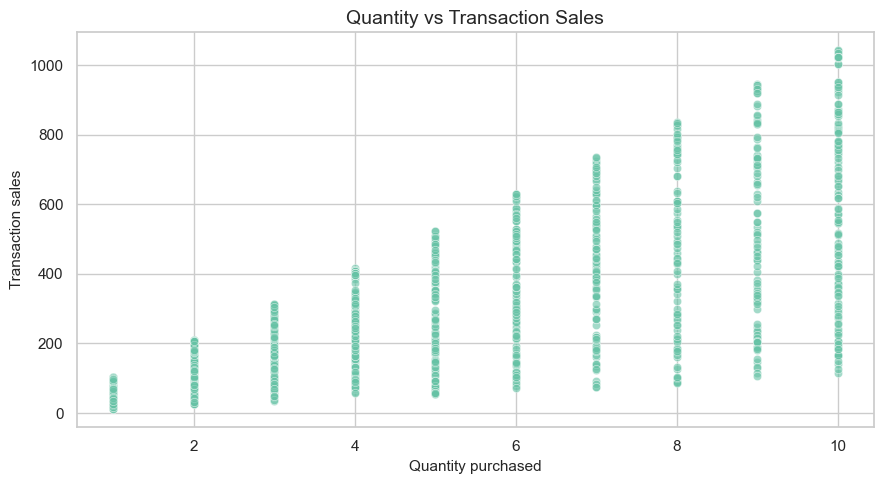

In [21]:
if {"Quantity"}.issubset(df.columns) and sales_col:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=df, x="Quantity", y=sales_col, alpha=0.6)
    plt.title("Quantity vs Transaction Sales")
    plt.xlabel("Quantity purchased")
    plt.ylabel("Transaction sales")
    plt.tight_layout()
    plt.show()

### 6.13 Correlation Between Numeric Features

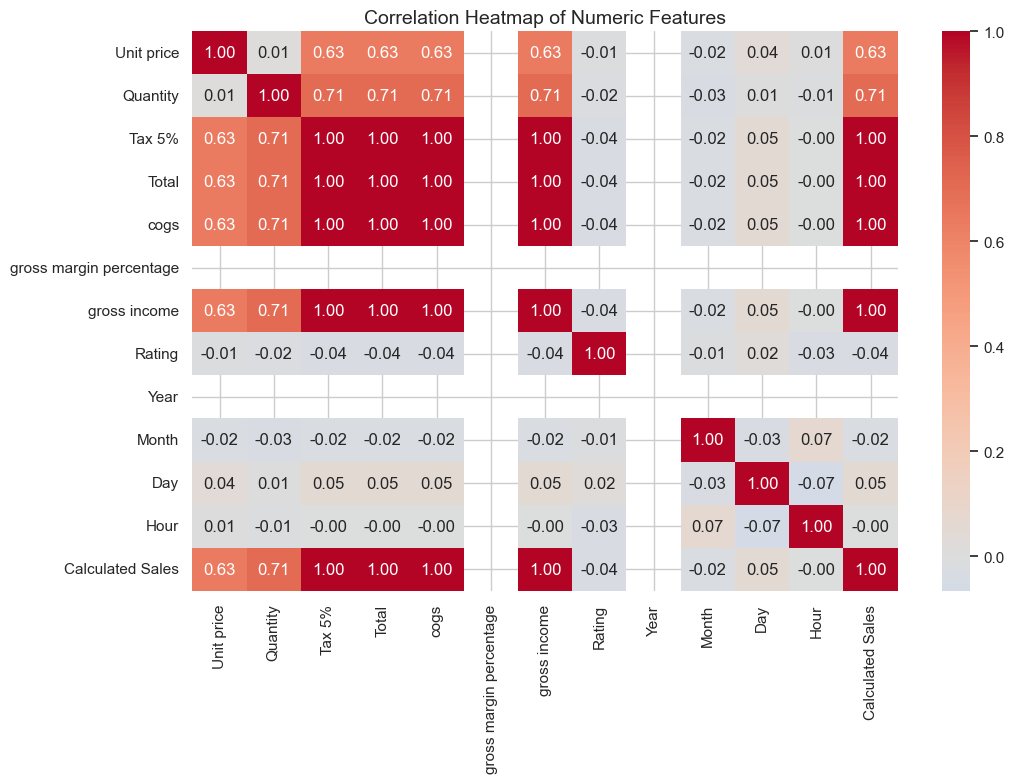

In [22]:
numeric_for_corr = df.select_dtypes(include="number").columns.tolist()
# Remove derived fields that duplicate the same measure only if desired; retain the available numeric features.
if len(numeric_for_corr) >= 2:
    corr = df[numeric_for_corr].corr()
    plt.figure(figsize=(11, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False)
    plt.title("Correlation Heatmap of Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation heatmap.")

## 7. Summary Tables for Further Analysis

In [23]:
if "Product line" in df.columns and sales_col:
    product_summary = df.groupby("Product line").agg(
        Transactions=(sales_col, "size"),
        Total_Sales=(sales_col, "sum"),
        Average_Sales=(sales_col, "mean")
    ).sort_values("Total_Sales", ascending=False)
    if "Rating" in df.columns:
        product_summary["Average_Rating"] = df.groupby("Product line")["Rating"].mean()
    display(product_summary.round(2))

,Transactions,Total_Sales,Average_Sales,Average_Rating
Product line,,,,
Food and beverages,174,56144.84,322.67,7.11
Sports and travel,166,55122.83,332.07,6.92
Electronic accessories,170,54337.53,319.63,6.92
Fashion accessories,178,54305.90,305.09,7.03
Home and lifestyle,160,53861.91,336.64,6.84
Health and beauty,152,49193.74,323.64,7.00


## 8. Interpretation & Reporting Notes

Use the output tables and charts to write findings based on the observed values. Avoid claiming that one factor causes another based only on correlations or group comparisons.

Suggested questions for the project README:
- Which product line contributes the most sales?
- Which city has the highest sales?
- Which payment method is used most often?
- At what time of day are sales highest?
- Which product line receives the strongest average ratings?
- Are any numerical variables strongly correlated?

**Reproducibility:** Run all cells from top to bottom, confirm there are no errors, then save the notebook so GitHub can display the static chart outputs.